# U1 · Divergencia BTC–SOL — Luz Milagros Huanca Pacco

**Proyecto:** CryptoPulse · Grupo 3 · Big Data UPeU 2026-2
**Pregunta central del equipo:** ¿Cómo puede un analista de riesgo anticipar, con 5 a 30 minutos de antelación, condiciones de riesgo en BTC y SOL: volatilidad alta, caídas fuertes, actividad anómala y desacople entre ambos activos?

**Dimensión U1 (batch, descriptiva/diagnóstica + predictiva):** ¿Cuánto se separaron históricamente los rendimientos de SOL y BTC, cuándo se desacoplan más, y qué tamaño de separación |SOL − BTC| se puede esperar en los próximos 15 minutos?

- **Indicador:** Separación |SOL − BTC| a 15 min en puntos porcentuales: media y P95 mensual; separación estimada por un modelo de regresión.
- **Decisión que habilita:** Detectar desacoplamientos para revisar coberturas o rotación entre ambos activos.
- **Fuente batch:** Binance Public Data, velas de 1 minuto BTCUSDT y SOLUSDT, enero 2022 – septiembre 2026 (4 993 759 filas, ZIP con SHA256 verificado).
- **Relación con U2:** el mismo modelo y las mismas variables se aplican en vivo en Grafana, panel *Separación BTC–SOL · tamaño |SOL − BTC| a 15 min*.

Este notebook corre de punta a punta sin intervención manual, sobre los datos reales que deja el pipeline (`scripts/entrenar_producto.ps1`).

## 0. Sesión Spark

In [1]:
import sys, json, math
sys.path.insert(0, "/opt")
from pathlib import Path
from operator import add
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, LongType, DecimalType, StringType
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from cryptopulse.core import get_spark, ROOT, CLEAN, ML, FEATURES, TRAIN_END, VALIDATION_END
%matplotlib inline

spark = get_spark("u1-divergencia", memory="3g", cores=4)
SALIDA = Path("/opt/u1-dimensiones/artifacts/divergencia")
SALIDA.mkdir(parents=True, exist_ok=True)
print("Spark", spark.version, "| salida:", SALIDA)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 16:23:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | salida: /opt/u1-dimensiones/artifacts/divergencia


## 1. Extracción con esquema explícito y evaluación perezosa

Se lee un archivo mensual crudo (`SOLUSDT-1m-2025-01.csv`) con `StructType`, sin dejar que Spark adivine tipos. Desde 2025 Binance publica los tiempos en microsegundos, por eso se dividen entre 1000.

In [2]:
ESQUEMA = StructType([StructField("open_time_raw", LongType())] +
    [StructField(c, DecimalType(28, 8)) for c in ["open", "high", "low", "close", "volume"]] +
    [StructField("close_time_raw", LongType()), StructField("quote_asset_volume", DecimalType(28, 8)),
     StructField("number_of_trades", LongType()), StructField("taker_buy_base_volume", DecimalType(28, 8)),
     StructField("taker_buy_quote_volume", DecimalType(28, 8)), StructField("ignore", StringType())])

crudo = spark.read.schema(ESQUEMA).option("mode", "FAILFAST").csv(str(ROOT / "s02-fundamentos/data/raw/SOLUSDT-1m-2025-01.csv"))
velas = (crudo
    .withColumn("open_ms", F.expr("open_time_raw DIV 1000"))
    .withColumn("event_time", F.timestamp_millis("open_ms"))
    .withColumn("rango_pct", 100 * (F.col("high") - F.col("low")) / F.col("open"))
    .withColumn("hora_utc", F.hour("event_time")))
velas.printSchema()

root
 |-- open_time_raw: long (nullable = true)
 |-- open: decimal(28,8) (nullable = true)
 |-- high: decimal(28,8) (nullable = true)
 |-- low: decimal(28,8) (nullable = true)
 |-- close: decimal(28,8) (nullable = true)
 |-- volume: decimal(28,8) (nullable = true)
 |-- close_time_raw: long (nullable = true)
 |-- quote_asset_volume: decimal(28,8) (nullable = true)
 |-- number_of_trades: long (nullable = true)
 |-- taker_buy_base_volume: decimal(28,8) (nullable = true)
 |-- taker_buy_quote_volume: decimal(28,8) (nullable = true)
 |-- ignore: string (nullable = true)
 |-- open_ms: long (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- rango_pct: decimal(38,6) (nullable = true)
 |-- hora_utc: integer (nullable = true)



In [3]:
# Transformaciones: Spark solo arma el plan, todavía no lee el archivo.
resumen_hora = (velas.filter(F.col("number_of_trades") > 0)
    .groupBy("hora_utc")
    .agg(F.count("*").alias("velas"), F.avg("rango_pct").alias("rango_medio_pct"),
         F.sum(F.col("quote_asset_volume").cast("double")).alias("usdt_negociado")))
resumen_hora.explain(True)

== Parsed Logical Plan ==
'Aggregate ['hora_utc], ['hora_utc, 'count(*) AS velas#17, 'avg('rango_pct) AS rango_medio_pct#18, 'sum(cast('quote_asset_volume as double)) AS usdt_negociado#19]
+- Filter (number_of_trades#8L > cast(0 as bigint))
   +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, rango_pct#15, hour(event_time#14, Some(UTC)) AS hora_utc#16]
      +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume#9, taker_buy_quote_volume#10, ignore#11, open_ms#13L, event_time#14, (((high#2 - low#3) * cast(100 as decimal(3,0))) / open#1) AS rango_pct#15]
         +- Project [open_time_raw#0L, open#1, high#2, low#3, close#4, volume#5, close_time_raw#6L, quote_asset_volume#7, number_of_trades#8L, taker_buy_base_volume

In [4]:
# La acción (toPandas) es el momento en que Spark ejecuta el plan de verdad.
tabla_hora = resumen_hora.orderBy("hora_utc").toPandas()
tabla_hora.head(24)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,hora_utc,velas,rango_medio_pct,usdt_negociado
0,0,1860,0.1896743430,1.635260e+09
1,1,1860,0.1701765274,1.345513e+09
2,2,1860,0.1632560597,1.408459e+09
3,3,1860,0.1546336839,1.406611e+09
4,4,1860,0.1590655887,1.724720e+09
5,5,1860,0.1514160011,1.548760e+09
6,6,1860,0.1518108801,1.611726e+09
7,7,1860,0.1489165022,1.624913e+09
8,8,1860,0.1565767667,1.571467e+09
9,9,1860,0.1594432774,1.773029e+09


## 2. Calidad de datos: nulos y duplicados

**Decisión documentada:** no se imputan precios ni se fabrican velas. Una fila con un campo obligatorio nulo se descarta (en S03 va a cuarentena) y, si un mismo minuto aparece dos veces, se conserva una sola fila identificada con `row_number()`.

In [5]:
OBLIGATORIAS = ["open", "high", "low", "close", "volume", "quote_asset_volume", "number_of_trades"]
nulos = velas.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in OBLIGATORIAS])
nulos.show()

ventana = Window.partitionBy("open_ms").orderBy(F.col("number_of_trades").desc())
duplicados = velas.withColumn("fila", F.row_number().over(ventana)).filter("fila > 1").count()
limpio = velas.na.drop(subset=OBLIGATORIAS).dropDuplicates(["open_ms"])
filas_crudas, filas_limpias = velas.count(), limpio.count()
print(f"Duplicados por minuto: {duplicados} | filas crudas {filas_crudas} -> limpias {filas_limpias}")

s03 = json.loads((ROOT / "_runtime/s03.json").read_text(encoding="utf-8"))
print(f"Pipeline completo S03: {s03['input_rows']:,} filas -> {s03['clean_rows']:,} válidas, "
      f"{s03['invalid_rows']} en cuarentena, {s03['gaps']['gaps']} huecos ({s03['gaps']['missing_minutes']:.0f} min)")

+----+----+---+-----+------+------------------+----------------+
|open|high|low|close|volume|quote_asset_volume|number_of_trades|
+----+----+---+-----+------+------------------+----------------+
|   0|   0|  0|    0|     0|                 0|               0|
+----+----+---+-----+------+------------------+----------------+



Duplicados por minuto: 0 | filas crudas 44640 -> limpias 44640
Pipeline completo S03: 4,993,759 filas -> 4,993,757 válidas, 2 en cuarentena, 3 huecos (163 min)


## 3. Parquet particionado y verificación de ida y vuelta

El lago limpio está particionado por `symbol/year/month`. Se filtra la misma partición del archivo crudo y se confirma en el plan físico que Spark solo lee esa carpeta (`PartitionFilters`), y que el conteo coincide con el crudo limpio.

In [6]:
lago = spark.read.parquet(str(CLEAN))
particion = lago.filter((F.col("symbol") == "SOLUSDT") & (F.col("year") == 2025) & (F.col("month") == 1))
plan = particion._jdf.queryExecution().executedPlan().toString()
linea = next(l for l in plan.splitlines() if "PartitionFilters" in l)
print(linea[linea.index("PartitionFilters"):][:260])
assert "PartitionFilters: [" in plan and "SOLUSDT" in plan

filas_particion = particion.count()
print(f"Partición SOLUSDT 2025-01: {filas_particion} filas | crudo limpio: {filas_limpias}")
assert filas_particion == filas_limpias, "La lectura de vuelta no reconcilia con el crudo"

PartitionFilters: [isnotnull(symbol#256), isnotnull(year#257), isnotnull(month#258), (symbol#256 = SOLUSDT), (year#..., PushedFilters: [], ReadSchema: struct<open_time_raw:bigint,open:decimal(28,8),high:decimal(28,8),low:decimal(28,8),close:decimal...


Partición SOLUSDT 2025-01: 44640 filas | crudo limpio: 44640


## 4. Procesamiento con RDD

In [7]:
# Distribución del rango intravela (alto-bajo) en tramos de 0.1 %, con map/reduceByKey.
tramos = (limpio.select("rango_pct").rdd
    .map(lambda r: (min(int(float(r.rango_pct) * 10), 10), 1))
    .reduceByKey(add)
    .sortByKey()
    .collect())
for tramo, n in tramos:
    etiqueta = f">= {tramo/10:.1f} %" if tramo == 10 else f"{tramo/10:.1f}–{(tramo+1)/10:.1f} %"
    print(f"{etiqueta:>12}: {n:6d} velas")

   0.0–0.1 %:  16198 velas
   0.1–0.2 %:  16099 velas
   0.2–0.3 %:   6348 velas
   0.3–0.4 %:   2784 velas
   0.4–0.5 %:   1333 velas
   0.5–0.6 %:    713 velas
   0.6–0.7 %:    401 velas
   0.7–0.8 %:    237 velas
   0.8–0.9 %:    168 velas
   0.9–1.0 %:    114 velas
    >= 1.0 %:    245 velas


## 5. Análisis descriptivo y diagnóstico (2022 – 2026)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


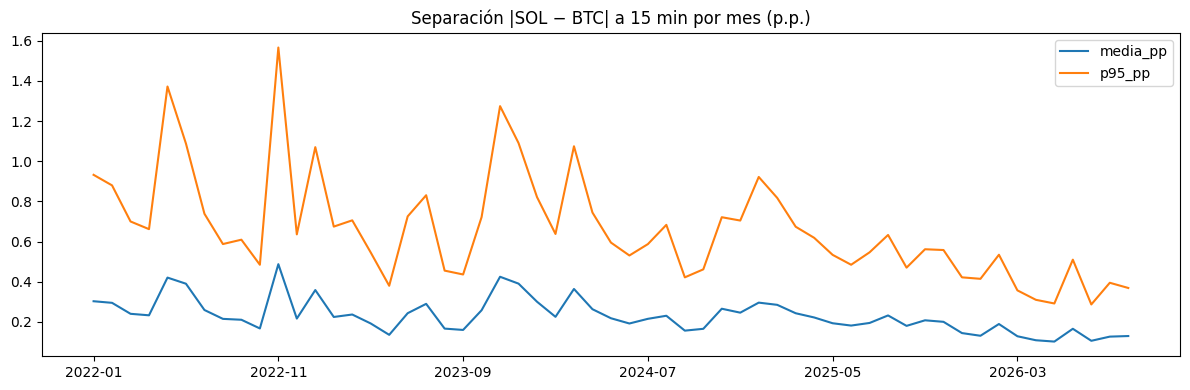

,mes,media_pp,p95_pp,correlacion_media
45,2025-10,0.208065,0.561909,0.717268
46,2025-11,0.200521,0.558056,0.766315
47,2025-12,0.144433,0.422002,0.733813
48,2026-01,0.131079,0.414649,0.716687
49,2026-02,0.189563,0.534531,0.818195
50,2026-03,0.128650,0.357139,0.824408
51,2026-04,0.108714,0.310098,0.765831
52,2026-05,0.102129,0.291853,0.772586
53,2026-06,0.165846,0.510031,0.826353
54,2026-07,0.106016,0.287029,0.751967


In [8]:
pares = (spark.read.parquet(str(ML / "pair_dataset"))
    .withColumn("separacion", F.abs("target_divergence"))
    .withColumn("mes", F.date_format(F.timestamp_millis("open_ms"), "yyyy-MM")))
mensual = (pares.groupBy("mes").agg(F.avg("separacion").alias("media_pp"),
    F.percentile_approx("separacion", 0.95).alias("p95_pp"), F.avg("correlation_60m").alias("correlacion_media"))
    .orderBy("mes").toPandas())
ax = mensual.plot(x="mes", y=["media_pp", "p95_pp"], figsize=(12, 4), title="Separación |SOL − BTC| a 15 min por mes (p.p.)")
ax.set_xlabel(""); plt.tight_layout(); plt.show()
mensual.tail(12)

**Diagnóstico:** ¿la separación crece cuando BTC y SOL dejan de moverse juntos? Se agrupa por tramo de correlación de la última hora.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


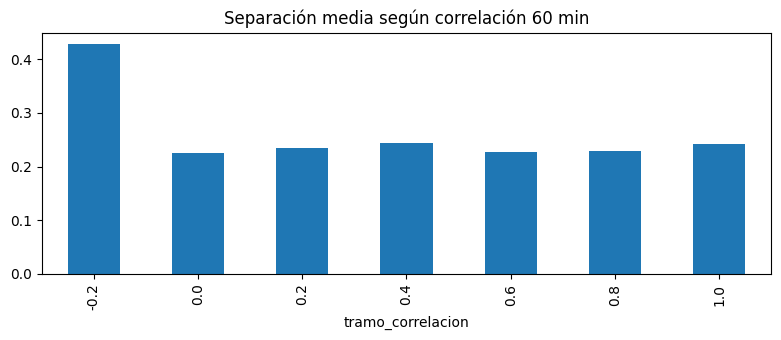

,tramo_correlacion,n,separacion_media_pp
0,-0.2,25,0.427803
1,0.0,488,0.224696
2,0.2,3597,0.235092
3,0.4,15669,0.243544
4,0.6,53465,0.228010
5,0.8,88507,0.228591
6,1.0,4693,0.241241


In [9]:
diag = (pares.withColumn("tramo_correlacion", F.round(F.col("correlation_60m") * 5) / 5)
    .groupBy("tramo_correlacion").agg(F.count("*").alias("n"), F.avg("separacion").alias("separacion_media_pp"))
    .orderBy("tramo_correlacion").toPandas())
diag.plot.bar(x="tramo_correlacion", y="separacion_media_pp", figsize=(8, 3.5), legend=False,
              title="Separación media según correlación 60 min"); plt.tight_layout(); plt.show()
diag

## 6. Modelo predictivo distribuido (Spark MLlib)

Partición temporal sin fuga de información: **entrenamiento 2022–2024**, **validación 2025**, **prueba enero–septiembre 2026**, con un embargo de 30 minutos entre tramos. El ganador se elige solo con validación; la prueba se usa una vez, al final.

In [10]:
base = (spark.read.parquet(str(ML / "pair_dataset"))
    .withColumn("label", F.abs("target_divergence")).withColumn("abs_spread15", F.abs("current_spread15")))
COLUMNAS = [c for c in base.columns if c.startswith(("btc_", "sol_"))] + ["correlation_60m", "current_spread15", "abs_spread15"]

In [11]:
entrenamiento = base.filter(F.col("open_ms") + 1800000 < TRAIN_END).cache()
validacion = base.filter((F.col("open_ms") >= TRAIN_END) & (F.col("open_ms") + 1800000 < VALIDATION_END)).cache()
prueba = base.filter(F.col("open_ms") >= VALIDATION_END).cache()
print({"entrenamiento": entrenamiento.count(), "validacion": validacion.count(), "prueba": prueba.count()})

{'entrenamiento': 105195, 'validacion': 35038, 'prueba': 26207}


In [12]:
ensamblador = VectorAssembler(inputCols=COLUMNAS, outputCol="features")
CANDIDATOS = {
    "ridge": LinearRegression(regParam=0.1, elasticNetParam=0.0, maxIter=40),
    "lasso": LinearRegression(regParam=0.01, elasticNetParam=1.0, maxIter=40),
    "random_forest": RandomForestRegressor(numTrees=30, maxDepth=6, minInstancesPerNode=30, seed=26),
}
METRICAS = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m) for m in ("rmse", "mae", "r2")}
media_entrenamiento = entrenamiento.agg(F.avg("label")).first()[0]
REFERENCIA = F.lit(media_entrenamiento)

def evaluar(df):
    df = df.withColumn("prediction", F.greatest(F.lit(0.0), F.col("prediction")))
    return {m: float(e.evaluate(df)) for m, e in METRICAS.items()}

modelos, resultados_val = {}, {}
resultados_val["referencia"] = evaluar(validacion.withColumn("prediction", REFERENCIA))
for nombre, estimador in CANDIDATOS.items():
    modelos[nombre] = Pipeline(stages=[ensamblador, estimador]).fit(entrenamiento)
    resultados_val[nombre] = evaluar(modelos[nombre].transform(validacion))
tabla_val = pd.DataFrame(resultados_val).T.sort_values("rmse")
ganador = min(CANDIDATOS, key=lambda n: resultados_val[n]["rmse"])
print("Referencia:", "promedio histórico de entrenamiento", "| ganador en validación:", ganador)
tabla_val

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


Referencia: promedio histórico de entrenamiento | ganador en validación: lasso


,rmse,mae,r2
lasso,0.217161,0.142415,0.176714
random_forest,0.217906,0.141298,0.171061
ridge,0.218670,0.147083,0.165236
referencia,0.243586,0.168271,-0.035832


Prueba 2026: RMSE lasso 0.1485 vs referencia 0.1978 (+24.9 %)


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


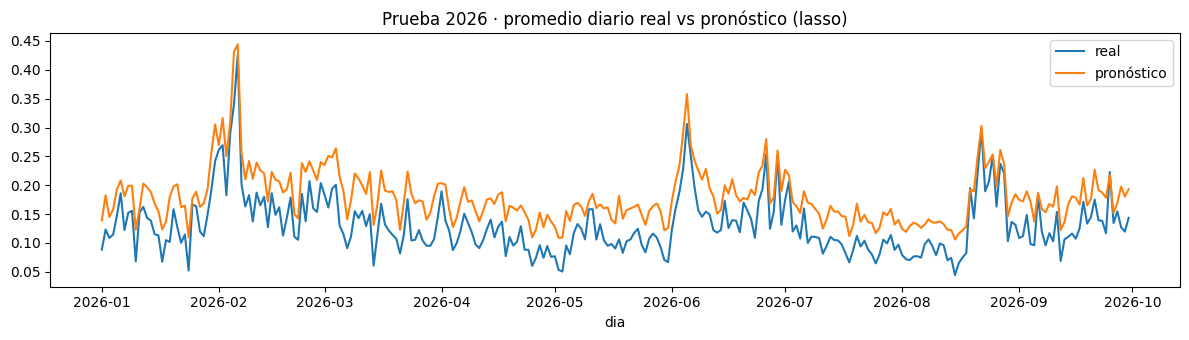

,rmse,mae,r2
lasso,0.148539,0.105970,0.021843
referencia,0.197819,0.169534,-0.734856


In [13]:
predicciones = modelos[ganador].transform(prueba).withColumn("prediction", F.greatest(F.lit(0.0), F.col("prediction")))
resultados_test = {ganador: evaluar(predicciones), "referencia": evaluar(prueba.withColumn("prediction", REFERENCIA))}
mejora = 100 * (1 - resultados_test[ganador]["rmse"] / resultados_test["referencia"]["rmse"])
print(f"Prueba 2026: RMSE {ganador} {resultados_test[ganador]['rmse']:.4f} vs referencia "
      f"{resultados_test['referencia']['rmse']:.4f} ({mejora:+.1f} %)")
diario = (predicciones.withColumn("dia", F.to_date(F.timestamp_millis("open_ms")))
    .groupBy("dia").agg(F.avg("label").alias("real"), F.avg("prediction").alias("pronóstico")).orderBy("dia").toPandas())
diario.plot(x="dia", figsize=(12, 3.5), title=f"Prueba 2026 · promedio diario real vs pronóstico ({ganador})")
plt.tight_layout(); plt.show()
pd.DataFrame(resultados_test).T

In [14]:
# Se guarda el modelo que ganó en validación (no el primero entrenado) y se comprueba que recarga.
ruta = str(SALIDA / "modelo_ganador")
modelos[ganador].write().overwrite().save(ruta)
recargado = PipelineModel.load(ruta)
print("Modelo guardado y recargado:", ruta, "| etapas:", [type(s).__name__ for s in recargado.stages])

Modelo guardado y recargado: /opt/u1-dimensiones/artifacts/divergencia/modelo_ganador | etapas: ['VectorAssembler', 'LinearRegressionModel']


## 7. Registro de la verificación

In [15]:
verificacion = {"dimension": "divergencia", "integrante": "Luz Milagros Huanca Pacco", "status": "PASS",
    "filas_crudas": filas_crudas, "filas_particion": filas_particion, "duplicados": duplicados,
    "modelo_ganador": ganador, "metricas_validacion": resultados_val, "metricas_prueba": resultados_test,
    "modelo_guardado": str(SALIDA / "modelo_ganador")}
(SALIDA / "verificacion_u1.json").write_text(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print(json.dumps(verificacion, indent=2, ensure_ascii=False, default=float))
spark.stop()

{
  "dimension": "divergencia",
  "integrante": "Luz Milagros Huanca Pacco",
  "status": "PASS",
  "filas_crudas": 44640,
  "filas_particion": 44640,
  "duplicados": 0,
  "modelo_ganador": "lasso",
  "metricas_validacion": {
    "referencia": {
      "rmse": 0.24358581845412386,
      "mae": 0.16827117994155655,
      "r2": -0.035832427562258795
    },
    "ridge": {
      "rmse": 0.21866990883327844,
      "mae": 0.1470831554746183,
      "r2": 0.16523630955237378
    },
    "lasso": {
      "rmse": 0.21716140012258256,
      "mae": 0.1424152109092766,
      "r2": 0.17671392713233447
    },
    "random_forest": {
      "rmse": 0.21790565553506575,
      "mae": 0.14129822859775115,
      "r2": 0.17106112605344148
    }
  },
  "metricas_prueba": {
    "lasso": {
      "rmse": 0.14853887667645668,
      "mae": 0.10596953154020687,
      "r2": 0.02184317492158172
    },
    "referencia": {
      "rmse": 0.19781882327526293,
      "mae": 0.16953392848792406,
      "r2": -0.7348560595122726